In [4]:
import numpy as np
from scipy.special import softmax
from scipy import stats
import matplotlib.pyplot as plt

In [5]:
class ASinhMax:
    """Inverse hyperbolic sine activation"""
    def __init__(self, alpha=1.0, beta=1.0):
        self.alpha = alpha
        self.beta = beta

    def __call__(self, x):
        top = np.arcsinh(x / self.alpha)
        bottom = np.arcsinh(self.beta / self.alpha)
        return top / bottom

    def inverse(self, x):
        value = x * np.arcsinh(self.beta / self.alpha)
        z = np.sign(x) * self.alpha * np.sinh(value)
        return np.where(x < 0, -z, z)


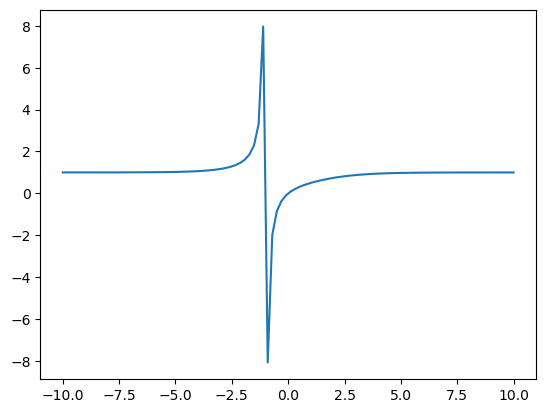

In [6]:
norm = ASinhMax(alpha=1, beta=1.0)

# plot softmax curve
x = np.linspace(-10, 10, 100)
z = np.stack([x, np.ones_like(x)])


asinh_max = norm.inverse(z) / norm.inverse(z).sum(axis=0, keepdims=True)

plt.plot(x, asinh_max[0])

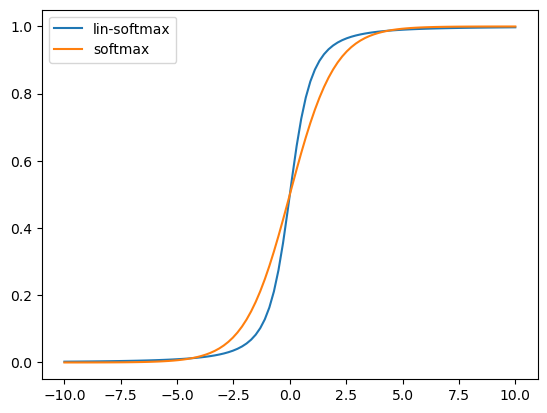

In [27]:
# plot softmax curve
def lin_softmax(x, axis=0):
    return 0.5 * ((x / np.sqrt((x ** 2).sum(axis=axis, keepdims=True))) + 1)


x = np.linspace(-10, 10, 100)
z = np.stack([x, np.ones_like(x)])
plt.plot(x, lin_softmax(z, axis=0)[0], label="lin-softmax")

# plot softmax curve
x = np.linspace(-10, 10, 100)
z = np.stack([x, np.zeros_like(x)])
plt.plot(x, softmax(z, axis=0)[0], label="softmax")
plt.legend()
plt.show()

In [34]:
x = np.random.randn(1000, 10)

In [50]:
logits = softmax(x, axis=1)
logits_lin = lin_softmax(x, axis=1)

In [51]:
logits_lin / logits_lin.sum(axis=1, keepdims=True)

array([[0.05080239, 0.08497115, 0.083496  , ..., 0.09915413, 0.08801535,
        0.10255358],
       [0.1639523 , 0.05229694, 0.08577841, ..., 0.10738298, 0.07042998,
        0.11541467],
       [0.10376125, 0.06339688, 0.07202149, ..., 0.11687927, 0.09435165,
        0.11794826],
       ...,
       [0.10088097, 0.16355045, 0.05467555, ..., 0.0791465 , 0.0476277 ,
        0.10341218],
       [0.1505945 , 0.08610669, 0.06579099, ..., 0.05081266, 0.08758049,
        0.11237403],
       [0.06633382, 0.10085949, 0.07843605, ..., 0.12588554, 0.09432913,
        0.07375211]])

In [52]:
logits

array([[0.01438155, 0.03828495, 0.03670035, ..., 0.05748202, 0.04177461,
        0.06336324],
       [0.42367868, 0.01374758, 0.03842975, ..., 0.07460064, 0.02398899,
        0.0954634 ],
       [0.07700506, 0.02472117, 0.03151403, ..., 0.11140012, 0.05908645,
        0.11480318],
       ...,
       [0.06620051, 0.38829143, 0.01796412, ..., 0.03584327, 0.01472322,
        0.07110378],
       [0.23485578, 0.05683458, 0.03634911, ..., 0.02614412, 0.05870768,
        0.10129782],
       [0.02989497, 0.07526476, 0.04131976, ..., 0.14697827, 0.06320417,
        0.03645498]])